Today's topics:
* one reading's share of the sum of squared residuals
* mean absolute error as an objective for `minimize`
* comparing least-squares and minimum-MAE fits
* fitting one batch separately from the pooled data

# A catalyst screening campaign

A catalyst helps convert carbon dioxide into other molecules, including methanol.
In a screening campaign, researchers made many catalyst formulations and measured
how much of the incoming CO₂ reacted.

Today we will fit a line, inspect one deliberately mistyped value,
and ask what the real low-conversion rows tell us.

*When a row sits far from a fit, what should we do with it?*

The data are from the [Swiss Cat+ CO₂ hydrogenation campaign](https://zenodo.org/records/8314734)
(Ramirez et al., CC BY 4.0). The table has 143 formulations tested at 275 °C.
`Total Metal Loading [wt%]` is the mass percentage of added metals in a catalyst.
`CO2 Conversion (%)` is the percentage of incoming CO₂ that reacted.

This campaign began with a mixed-support screening batch. Later batches were selected
by an optimizer and used ZrO₂ support. That history matters when we interpret a pooled line.

Let's load the table and plot conversion against metal loading:

143 catalyst formulations


Text(0, 0.5, 'CO₂ conversion (%)')

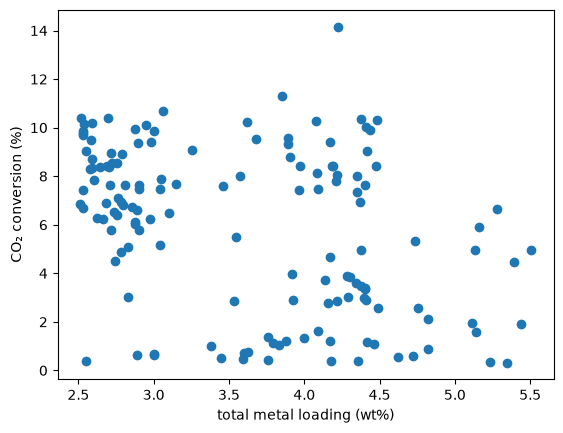

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/catalysis_swisscat_275c.csv')
loading = data['Total Metal Loading [wt%]'].to_numpy()
conversion = data['CO2 Conversion (%)'].to_numpy()
print(len(data), 'catalyst formulations')

fig, ax = plt.subplots()
ax.plot(loading, conversion, 'o')
ax.set_xlabel('total metal loading (wt%)')
ax.set_ylabel('CO₂ conversion (%)')

The cloud is broad. A line is only a rough summary of these formulations.
It does not tell us that adding more metal causes conversion to rise or fall.

Let's fit the clean, recorded table first:

In [2]:
fit_clean = stats.linregress(loading, conversion)
pred_clean = fit_clean.slope * loading + fit_clean.intercept
print(f'clean least-squares slope = {fit_clean.slope:.2f} percentage points per wt%')
print(f'R² = {fit_clean.rvalue**2:.2f}')

clean least-squares slope = -1.52 percentage points per wt%
R² = 0.15


# What one wrong value does

Here the recorded maximum conversion is 14.16%. We move its decimal point
and enter 141.58% instead.
Conversion above 100% is physically impossible, so the record tells us to correct it.
The original data file is unchanged:

In [3]:
bad_index = np.argmax(conversion)  # row with the largest recorded conversion
conversion_typo = conversion.copy()  # separate array; the recorded readings stay unchanged
conversion_typo[bad_index] = 10 * conversion_typo[bad_index]  # planted decimal-place error
print(f'recorded = {conversion[bad_index]:.2f}%, mistyped = {conversion_typo[bad_index]:.2f}%')

recorded = 14.16%, mistyped = 141.58%


Let's fit both arrays with least squares:

In [4]:
fit_typo = stats.linregress(loading, conversion_typo)
print(f'clean slope: {fit_clean.slope:.2f} percentage points per wt%')
print(f'typo slope:  {fit_typo.slope:.2f} percentage points per wt%')

clean slope: -1.52 percentage points per wt%
typo slope:  -0.77 percentage points per wt%


The one wrong value moves the slope from about -1.52 to -0.77.
How much of the typo fit's squared error comes from that one value?

In [5]:
pred_typo = fit_typo.slope * loading + fit_typo.intercept
residuals_typo = conversion_typo - pred_typo
squared_typo = residuals_typo**2
share_typo = squared_typo[bad_index] / np.sum(squared_typo)
print(f'planted typo supplies {100 * share_typo:.1f}% of the squared error')

planted typo supplies 92.6% of the squared error


The planted value supplies about 93% of the typo fit's squared error.
The sketch shows that row and both fitted lines:

We can instead minimize the average absolute size of the residuals:

# Mean absolute error as the target

We computed MAE after a fit in Lecture 13.
Here it becomes the one number that `minimize` tries to make small.
The function follows the objective recipe from Lecture 22:

In [6]:
def mae_line(params):
    m, b = params                                  # slope and intercept arrive together
    residuals = conversion_typo - (m * loading + b)  # measured minus predicted
    return np.mean(np.abs(residuals))             # average absolute miss

## Can you beat `minimize`?

Move the slope and intercept to lower MAE on the table with the planted typo.
Run this cell once in Colab to activate its sliders. Record your best MAE.
The plot stops at 20% conversion so the ordinary readings are visible; the
score still includes the planted 141.58% value.

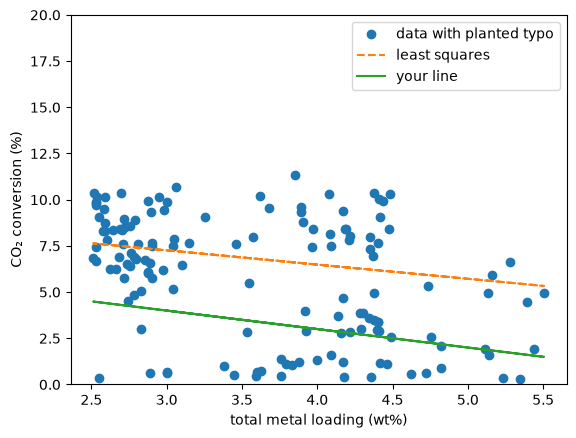

your MAE = 4.2552 percentage points


In [7]:
# @title Try to beat minimize {run:"auto"}
slope_guess = -1.0 # @param {type:"slider", min:-4.0, max:0.0, step:0.1}
intercept_guess = 7.0 # @param {type:"slider", min:5.0, max:20.0, step:0.5}

fig, ax = plt.subplots()
ax.plot(loading, conversion_typo, 'o', label='data with planted typo')
ax.plot(loading, fit_typo.slope * loading + fit_typo.intercept, '--', label='least squares')
ax.plot(loading, slope_guess * loading + intercept_guess, '-', label='your line')
ax.set_xlabel('total metal loading (wt%)')
ax.set_ylabel('CO₂ conversion (%)')
ax.set_ylim(0, 20)
ax.legend()
plt.show()
print(f'your MAE = {mae_line([slope_guess, intercept_guess]):.4f} percentage points')

> Recipe: for an absolute-value objective, use `method='Nelder-Mead'`.
> We copy this solver choice into the call; nobody needs to derive it today.

Start both parameters at 1 and compare the optimizer's MAE with yours:

In [8]:
res_mae = optimize.minimize(mae_line, [1, 1], method='Nelder-Mead')
m_mae, b_mae = res_mae.x
print(f'minimum-MAE slope = {m_mae:.2f}, intercept = {b_mae:.2f}')
print(f'minimum MAE = {res_mae.fun:.4f} percentage points, success = {res_mae.success}')

minimum-MAE slope = -2.36, intercept = 14.03
minimum MAE = 3.3879 percentage points, success = True


The minimum-MAE slope is about -2.36 despite the planted typo.
The least-squares slope on that same mistyped table is about -0.77.
Let's draw those two fits against the copied table with the typo:

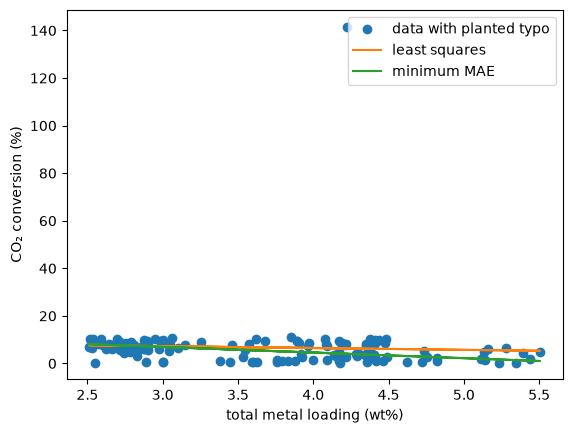

In [9]:
fig, ax = plt.subplots()
ax.plot(loading, conversion_typo, 'o', label='data with planted typo')
ax.plot(loading, fit_typo.slope * loading + fit_typo.intercept, '-', label='least squares')
ax.plot(loading, m_mae * loading + b_mae, '-', label='minimum MAE')
ax.set_xlabel('total metal loading (wt%)')
ax.set_ylabel('CO₂ conversion (%)')
ax.legend()

MAE reduces the influence of this wrong response value.
It does not fix the typo. We should restore the recorded value before reporting a fit.

### [Check your understanding] 1

How does the error grow?

1. Write a loop over `multipliers = [1, 2, 5, 10]`.
   For each multiplier, rebuild `conversion_typo` from `conversion`,
   multiply the one row at `bad_index`, and print the least-squares
   and minimum-MAE slopes. Use `method='Nelder-Mead'` and start at `[1, 1]`.
   Check: at multiplier 10, the slopes are about -0.77 and -2.36.
2. Which slope moves more as the planted error grows?

**Optional challenge:** explain why 141.58% could be caught before either fit.

# The real rows that sit low

Now return to the unmodified table. `Generation` records the campaign batch.
Generation 1 was the screening batch; the later generations were optimizer-selected.
Let's color those two groups and draw the pooled clean-data line:

24 screening formulations, 119 later formulations


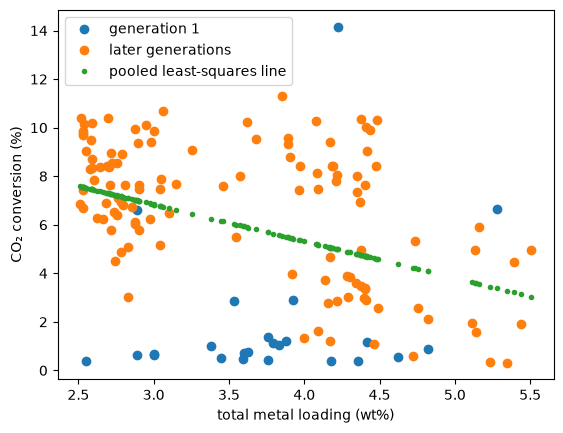

In [10]:
first = (data['Generation'] == '1').to_numpy()  # True on screening-batch rows
print(np.sum(first), 'screening formulations,', np.sum(~first), 'later formulations')

fig, ax = plt.subplots()
ax.plot(loading[first], conversion[first], 'o', label='generation 1')
ax.plot(loading[~first], conversion[~first], 'o', label='later generations')
ax.plot(loading, pred_clean, '.', label='pooled least-squares line')
ax.set_xlabel('total metal loading (wt%)')
ax.set_ylabel('CO₂ conversion (%)')
ax.legend()

The first batch is mostly below the pooled line.
Let's compare the median residual in each group:

In [11]:
residuals_clean = conversion - pred_clean
print(f'generation 1 median residual: {np.median(residuals_clean[first]):.2f} percentage points')
print(f'later generations median:     {np.median(residuals_clean[~first]):.2f} percentage points')

generation 1 median residual: -4.53 percentage points
later generations median:     0.86 percentage points


These are real experiments, not mistyped values.
The groups also differ in how formulations were selected. We cannot claim
that their support material alone caused the difference.
For a report about the screening batch, we would analyze that batch separately.

### [Check your understanding] 2

1. Use the `first` mask to fit a line to **Generation 1 only**
   with `stats.linregress`. That mask selects 24 of the 143 formulations.
2. Print its slope and R². Check: about +1.06 percentage points per wt% and R² about 0.05.
3. Compare its slope with the pooled line's -1.52. Does either line show
   that adding metal causes conversion to change? Why not?

**Optional challenge:** explain why a first-batch row below the pooled line
is not automatically a recording error.

# A real result far from the line

The planted 141.58% value was wrong, so we restored the recorded table.
That same formulation still has the highest measured conversion. Is its
remaining distance from the clean-data line another reason to remove it?

Find the largest absolute residual and open that formulation's record:

In [12]:
far_index = np.argmax(np.abs(residuals_clean))  # position of the largest miss
print(f'row {far_index}: residual = {residuals_clean[far_index]:+.2f} percentage points')
columns = ['Generation', 'Support', 'Total Metal Loading [wt%]',
           'Co Loading [wt%]', 'CO2 Conversion (%)',
           'MeOH Selectivity (%)', 'CH4 Selectivity(%)']
print(data.loc[far_index, columns])

row 10: residual = +9.17 percentage points
Generation                           1
Support                           ZrO2
Total Metal Loading [wt%]     4.222454
Co Loading [wt%]              3.053739
CO2 Conversion (%)            14.15811
MeOH Selectivity (%)          0.542407
CH4 Selectivity(%)           74.128775
Name: 10, dtype: object


**Conversion** says how much CO₂ reacted. **Selectivity** says what the reacted
carbon became. This real formulation converted 14.16% of the feed, the most
in this table, but only 0.54% of the reacted carbon became methanol;
74.13% became methane.
It contains cobalt and other ingredients, so this one row cannot identify
which ingredient caused that product mix.

Compare it with the campaign's typical methanol selectivity:

In [13]:
print(f'campaign median methanol selectivity: {data["MeOH Selectivity (%)"].median():.2f}%')

campaign median methanol selectivity: 34.83%


If the goal is **methanol**, would you call the formulation with the highest
CO₂ conversion the best candidate? Would you delete it as a bad measurement?
Discuss both answers with the person next to you before running on.

We can combine conversion and selectivity to estimate the percentage of the
incoming CO₂ that became methanol: conversion × methanol selectivity / 100.
Compare the highest-conversion row with the row that maximizes that estimate:

In [14]:
methanol_selectivity = data['MeOH Selectivity (%)'].to_numpy()
methanol_from_feed = conversion * methanol_selectivity / 100
best_methanol_index = np.argmax(methanol_from_feed)
print(f'highest-conversion row {far_index}: {methanol_from_feed[far_index]:.2f}% of feed to methanol')
print(f'best methanol row {best_methanol_index}: {methanol_from_feed[best_methanol_index]:.2f}% of feed to methanol')

highest-conversion row 10: 0.08% of feed to methanol
best methanol row 102: 4.32% of feed to methanol


The recorded value is possible and its product mix gives the result context.
Keep the row. High conversion alone does not make it a good methanol catalyst.
For a methanol search, the second row sends much more of the feed to methanol.
This comparison is descriptive; it does not prove which ingredient caused it.

# Correct, keep, or separate

* **Correct** the planted 141.58% typo because the original record and the 100% limit identify it.
* **Keep** the real high-conversion, methane-selective formulation after checking its record.
* **Separate** the screening batch when the question is about that batch alone.

A point's distance from a line is a reason to investigate it, not a reason to erase it.
Write down the reason for every data decision.

## Further reading

* [Swiss Cat+ catalyst campaign data and methods](https://zenodo.org/records/8314734).
* [SciPy: minimize](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html).